In [5]:
import pandas as pd

try:
    df = pd.read_csv('/manufacturing_data.csv')
    print("Successfully loaded '/manufacturing_data.csv'")
    display(df.head())
except FileNotFoundError:
    try:
        # Check if it was uploaded to current working directory instead of root
        df = pd.read_csv('manufacturing_data.csv')
        print("Successfully loaded 'manufacturing_data.csv'")
        display(df.head())
    except FileNotFoundError as e:
        print("Could not find the file at '/manufacturing_data.csv' or 'manufacturing_data.csv'.")
        print("Please verify that the file has uploaded completely and is placed in the correct directory.")

Successfully loaded '/manufacturing_data.csv'


,Batch_ID,Steel_kg,Aluminium_kg,Copper_kg,Plastic_kg,Machine_Hours,Worker_Hours,Temperature_C,Production_Output,Quality_Score,Defective
0,B001,543,100.2,46.8,23.7,23.2,82.9,29.4,518,93.0,1
1,B002,403,76.1,33.3,16.3,17.1,67.6,27.4,375,96.6,0
2,B003,381,80.1,29.5,17.7,16.4,59.9,29.6,353,90.5,0
3,B004,468,95.5,40.8,23.8,21.4,89.5,25.8,456,100.0,0
4,B005,600,116.7,46.7,24.6,27.9,112.7,31.9,588,90.6,0


In [9]:
print(f"Dataset shape: {df.shape}")
print("\n--- Dataset Info ---")
df.info()
print("\n--- First 5 Rows ---")
display(df.head())

Dataset shape: (200, 11)

--- Dataset Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Batch_ID           200 non-null    object 
 1   Steel_kg           200 non-null    int64  
 2   Aluminium_kg       200 non-null    float64
 3   Copper_kg          200 non-null    float64
 4   Plastic_kg         200 non-null    float64
 5   Machine_Hours      200 non-null    float64
 6   Worker_Hours       200 non-null    float64
 7   Temperature_C      200 non-null    float64
 8   Production_Output  200 non-null    int64  
 9   Quality_Score      200 non-null    float64
 10  Defective          200 non-null    int64  
dtypes: float64(7), int64(3), object(1)
memory usage: 17.3+ KB

--- First 5 Rows ---


,Batch_ID,Steel_kg,Aluminium_kg,Copper_kg,Plastic_kg,Machine_Hours,Worker_Hours,Temperature_C,Production_Output,Quality_Score,Defective
0,B001,543,100.2,46.8,23.7,23.2,82.9,29.4,518,93.0,1
1,B002,403,76.1,33.3,16.3,17.1,67.6,27.4,375,96.6,0
2,B003,381,80.1,29.5,17.7,16.4,59.9,29.6,353,90.5,0
3,B004,468,95.5,40.8,23.8,21.4,89.5,25.8,456,100.0,0
4,B005,600,116.7,46.7,24.6,27.9,112.7,31.9,588,90.6,0


In [10]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# Prepare features and target
# Dropping non-numeric identifiers 'Batch_ID' and our target 'Defective'
X = df.drop(columns=['Batch_ID', 'Defective'])
y = df['Defective']

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Scale features (critical for optimal SVM performance)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Initialize and train Linear SVM
svm_model = LinearSVC(random_state=42, max_iter=10000)
svm_model.fit(X_train_scaled, y_train)

# Predictions
y_pred = svm_model.predict(X_test_scaled)

# Evaluation
print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))

Accuracy: 0.875

Confusion Matrix:
 [[35  0]
 [ 5  0]]

Classification Report:
               precision    recall  f1-score   support

           0       0.88      1.00      0.93        35
           1       0.00      0.00      0.00         5

    accuracy                           0.88        40
   macro avg       0.44      0.50      0.47        40
weighted avg       0.77      0.88      0.82        40



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [11]:
# Initialize and train a Linear SVM with balanced class weights to address data imbalance
svm_balanced = LinearSVC(random_state=42, max_iter=20000, class_weight='balanced')
svm_balanced.fit(X_train_scaled, y_train)

# Predictions
y_pred_bal = svm_balanced.predict(X_test_scaled)

# Evaluation
print("Balanced Model Accuracy:", accuracy_score(y_test, y_pred_bal))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred_bal))
print("\nClassification Report:\n", classification_report(y_test, y_pred_bal))

Balanced Model Accuracy: 0.725

Confusion Matrix:
 [[27  8]
 [ 3  2]]

Classification Report:
               precision    recall  f1-score   support

           0       0.90      0.77      0.83        35
           1       0.20      0.40      0.27         5

    accuracy                           0.72        40
   macro avg       0.55      0.59      0.55        40
weighted avg       0.81      0.72      0.76        40



In [14]:
from sklearn.svm import SVC

# Initialize and train Non-Linear SVM with an RBF kernel and balanced class weights
svm_nonlinear = SVC(kernel='rbf', random_state=42, class_weight='balanced')
svm_nonlinear.fit(X_train_scaled, y_train)

# Predictions
y_pred_nl = svm_nonlinear.predict(X_test_scaled)

# Evaluation
print("Non-Linear SVM (RBF) Accuracy:", accuracy_score(y_test, y_pred_nl))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred_nl))
print("\nClassification Report:\n", classification_report(y_test, y_pred_nl))

Non-Linear SVM (RBF) Accuracy: 0.85

Confusion Matrix:
 [[32  3]
 [ 3  2]]

Classification Report:
               precision    recall  f1-score   support

           0       0.91      0.91      0.91        35
           1       0.40      0.40      0.40         5

    accuracy                           0.85        40
   macro avg       0.66      0.66      0.66        40
weighted avg       0.85      0.85      0.85        40



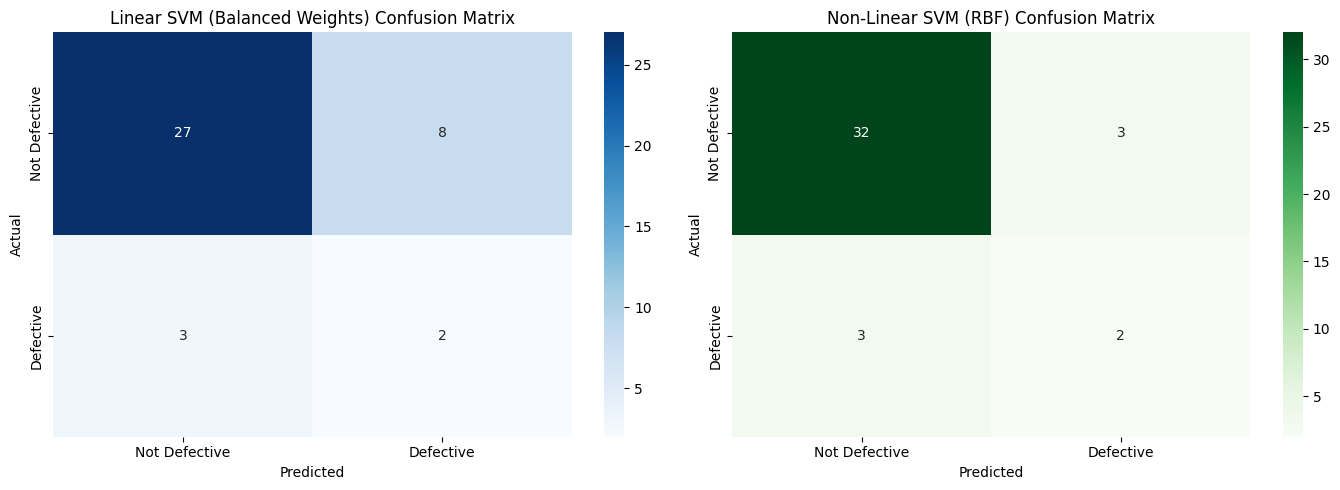

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, roc_curve, auc

# Calculate confusion matrices
cm_linear = confusion_matrix(y_test, y_pred_bal)
cm_nonlinear = confusion_matrix(y_test, y_pred_nl)

# Set up the plotting grid
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot Linear SVM Confusion Matrix
sns.heatmap(cm_linear, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['Not Defective', 'Defective'],
            yticklabels=['Not Defective', 'Defective'])
axes[0].set_title('Linear SVM (Balanced Weights) Confusion Matrix')
axes[0].set_ylabel('Actual')
axes[0].set_xlabel('Predicted')

# Plot Non-Linear SVM Confusion Matrix
sns.heatmap(cm_nonlinear, annot=True, fmt='d', cmap='Greens', ax=axes[1],
            xticklabels=['Not Defective', 'Defective'],
            yticklabels=['Not Defective', 'Defective'])
axes[1].set_title('Non-Linear SVM (RBF) Confusion Matrix')
axes[1].set_ylabel('Actual')
axes[1].set_xlabel('Predicted')

plt.tight_layout()
plt.show()

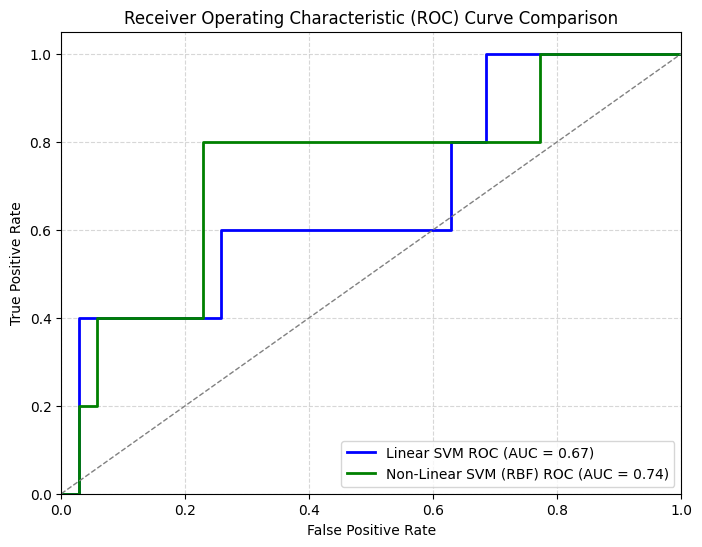

In [16]:
# Calculate decision function scores to plot ROC curves
y_score_linear = svm_balanced.decision_function(X_test_scaled)
y_score_nonlinear = svm_nonlinear.decision_function(X_test_scaled)

fpr_lin, tpr_lin, _ = roc_curve(y_test, y_score_linear)
roc_auc_lin = auc(fpr_lin, tpr_lin)

fpr_nl, tpr_nl, _ = roc_curve(y_test, y_score_nonlinear)
roc_auc_nl = auc(fpr_nl, tpr_nl)

# Plot ROC Curves
plt.figure(figsize=(8, 6))
plt.plot(fpr_lin, tpr_lin, color='blue', lw=2, label=f'Linear SVM ROC (AUC = {roc_auc_lin:.2f})')
plt.plot(fpr_nl, tpr_nl, color='green', lw=2, label=f'Non-Linear SVM (RBF) ROC (AUC = {roc_auc_nl:.2f})')
plt.plot([0, 1], [0, 1], color='gray', lw=1, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve Comparison')
plt.legend(loc="lower right")
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [17]:
import numpy as np

# 1. Show the Linear SVM Hyperplane Equation
# The equation of the hyperplane is: w1*x1 + w2*x2 + ... + wn*xn + b = 0
coefficients = svm_balanced.coef_[0]
intercept = svm_balanced.intercept_[0]
feature_names = X.columns

formula_parts = [f"({coef:.4f} * {name})" for coef, name in zip(coefficients, feature_names)]
hyperplane_equation = " + ".join(formula_parts) + f" + ({intercept:.4f}) = 0"

print("=== Linear SVM Hyperplane Formula (Normalized Features) ===")
print("0 = " + " + \n    ".join(formula_parts) + f" + \n    ({intercept:.4f})")
print("\nOr in standard vector form: W^T * X + b = 0")

=== Linear SVM Hyperplane Formula (Normalized Features) ===
0 = (0.5616 * Steel_kg) + 
    (-0.4607 * Aluminium_kg) + 
    (-0.5002 * Copper_kg) + 
    (-0.1091 * Plastic_kg) + 
    (-0.0703 * Machine_Hours) + 
    (-0.1398 * Worker_Hours) + 
    (0.1397 * Temperature_C) + 
    (0.6671 * Production_Output) + 
    (-0.2015 * Quality_Score) + 
    (-0.1457)

Or in standard vector form: W^T * X + b = 0


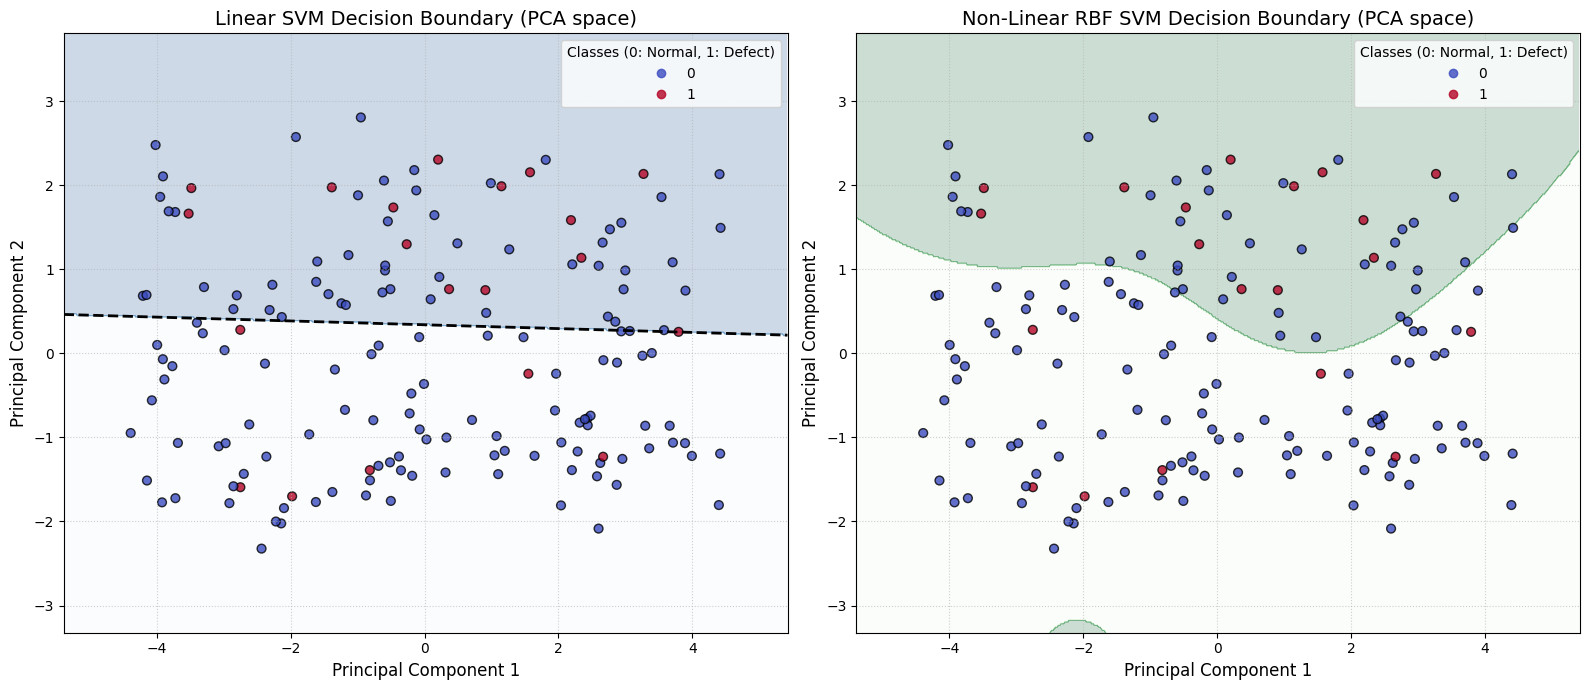

In [18]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import numpy as np

# 2. Project data into 2D using PCA for visualization purposes
pca = PCA(n_components=2)
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

# Retrain models in 2D to plot boundaries
svm_lin_2d = LinearSVC(random_state=42, max_iter=20000, class_weight='balanced')
svm_lin_2d.fit(X_train_pca, y_train)

svm_nl_2d = SVC(kernel='rbf', random_state=42, class_weight='balanced')
svm_nl_2d.fit(X_train_pca, y_train)

# Create a mesh grid to plot decision boundary contours
x_min, x_max = X_train_pca[:, 0].min() - 1, X_train_pca[:, 0].max() + 1
y_min, y_max = X_train_pca[:, 1].min() - 1, X_train_pca[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02), np.arange(y_min, y_max, 0.02))

# Plot setup
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
models = [svm_lin_2d, svm_nl_2d]
titles = ['Linear SVM Decision Boundary (PCA space)', 'Non-Linear RBF SVM Decision Boundary (PCA space)']
cmaps = [plt.cm.Blues, plt.cm.Greens]
colors = ['blue', 'green']

for i, (model, title, cmap, col) in enumerate(zip(models, titles, cmaps, colors)):
    # Predict over grid
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    # Plot contour of decision boundary
    axes[i].contourf(xx, yy, Z, alpha=0.2, cmap=cmap)

    # Plot training points
    scatter = axes[i].scatter(X_train_pca[:, 0], X_train_pca[:, 1], c=y_train,
                             cmap=plt.cm.coolwarm, edgecolors='k', s=40, alpha=0.8)

    # Highlight decision hyperplane / boundary line
    if hasattr(model, "coef_"):
        # For linear 2D model: w0*x + w1*y + b = 0 => y = -(w0*x + b)/w1
        w = model.coef_[0]
        b = model.intercept_[0]
        x_line = np.linspace(x_min, x_max, 100)
        y_line = -(w[0] * x_line + b) / w[1]
        axes[i].plot(x_line, y_line, color='black', lw=2, linestyle='--', label='Hyperplane (W^T*X + b = 0)')

    axes[i].set_title(title, fontsize=14)
    axes[i].set_xlabel('Principal Component 1', fontsize=12)
    axes[i].set_ylabel('Principal Component 2', fontsize=12)
    axes[i].set_xlim(x_min, x_max)
    axes[i].set_ylim(y_min, y_max)
    axes[i].legend(*scatter.legend_elements(), title="Classes (0: Normal, 1: Defect)")
    axes[i].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()